# Veri Bilimi Projeleri 2 - 1.6Milyon Trafik Kazası | Kız Başına Veri Analizi Bootcamp

Gerekli kütüphanelerin içe aktarılması ve data setinin yüklenmesi

In [52]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import warnings
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import LabelEncoder
from datetime import datetime, timedelta
warnings.filterwarnings('ignore')

df1 = pd.read_csv('/kaggle/input/2000-16-traffic-flow-england-scotland-wales/accidents_2005_to_2007.csv')
df2 = pd.read_csv('/kaggle/input/2000-16-traffic-flow-england-scotland-wales/accidents_2009_to_2011.csv')
df3 = pd.read_csv('/kaggle/input/2000-16-traffic-flow-england-scotland-wales/accidents_2012_to_2014.csv')
df = pd.concat([df1, df2, df3], ignore_index=True)

İlk ve son satırların görüntülenmesi,

In [53]:
df.head()

,Accident_Index,Location_Easting_OSGR,Location_Northing_OSGR,Longitude,Latitude,Police_Force,Accident_Severity,Number_of_Vehicles,Number_of_Casualties,Date,...,Pedestrian_Crossing-Physical_Facilities,Light_Conditions,Weather_Conditions,Road_Surface_Conditions,Special_Conditions_at_Site,Carriageway_Hazards,Urban_or_Rural_Area,Did_Police_Officer_Attend_Scene_of_Accident,LSOA_of_Accident_Location,Year
0,200501BS00001,525680.0,178240.0,-0.191170,51.489096,1,2,1,1,04/01/2005,...,Zebra crossing,Daylight: Street light present,Raining without high winds,Wet/Damp,NaN,NaN,1,Yes,E01002849,2005
1,200501BS00002,524170.0,181650.0,-0.211708,51.520075,1,3,1,1,05/01/2005,...,Pedestrian phase at traffic signal junction,Darkness: Street lights present and lit,Fine without high winds,Dry,NaN,NaN,1,Yes,E01002909,2005
2,200501BS00003,524520.0,182240.0,-0.206458,51.525301,1,3,2,1,06/01/2005,...,No physical crossing within 50 meters,Darkness: Street lights present and lit,Fine without high winds,Dry,NaN,NaN,1,Yes,E01002857,2005
3,200501BS00004,526900.0,177530.0,-0.173862,51.482442,1,3,1,1,07/01/2005,...,No physical crossing within 50 meters,Daylight: Street light present,Fine without high winds,Dry,NaN,NaN,1,Yes,E01002840,2005
4,200501BS00005,528060.0,179040.0,-0.156618,51.495752,1,3,1,1,10/01/2005,...,No physical crossing within 50 meters,Darkness: Street lighting unknown,Fine without high winds,Wet/Damp,NaN,NaN,1,Yes,E01002863,2005


In [54]:
df.tail()

,Accident_Index,Location_Easting_OSGR,Location_Northing_OSGR,Longitude,Latitude,Police_Force,Accident_Severity,Number_of_Vehicles,Number_of_Casualties,Date,...,Pedestrian_Crossing-Physical_Facilities,Light_Conditions,Weather_Conditions,Road_Surface_Conditions,Special_Conditions_at_Site,Carriageway_Hazards,Urban_or_Rural_Area,Did_Police_Officer_Attend_Scene_of_Accident,LSOA_of_Accident_Location,Year
1504145,2.01E+12,310037.0,597647.0,-3.417278,55.264773,98,2,2,1,07/12/2014,...,No physical crossing within 50 meters,Darkeness: No street lighting,Snowing without high winds,Snow,NaN,NaN,2,Yes,NaN,2014
1504146,2.01E+12,321509.0,574063.0,-3.230255,55.054855,98,3,2,2,11/12/2014,...,No physical crossing within 50 meters,Darkeness: No street lighting,Fine without high winds,Snow,NaN,NaN,2,Yes,NaN,2014
1504147,2.01E+12,321337.0,566365.0,-3.230826,54.985668,98,3,1,1,09/12/2014,...,No physical crossing within 50 meters,Darkness: Street lights present and lit,Fine without high winds,Frost/Ice,NaN,NaN,2,Yes,NaN,2014
1504148,2.01E+12,323869.0,566853.0,-3.191397,54.990446,98,2,3,2,17/12/2014,...,No physical crossing within 50 meters,Darkeness: No street lighting,Raining without high winds,Wet/Damp,NaN,NaN,2,Yes,NaN,2014
1504149,2.01E+12,314072.0,579971.0,-3.348426,55.106700,98,3,2,2,24/12/2014,...,No physical crossing within 50 meters,Daylight: Street light present,Fine without high winds,Wet/Damp,NaN,NaN,2,Yes,NaN,2014


Veri setinin boyutlarının incelenmesi için *df.shape fonksiyonu* kullanılmıştır.

In [55]:
df.shape

(1504150, 33)

Veri setinin yapısını ve özelliklerinin incelenmesi için *df.info() fonksiyonu* kullanılmıştır.

In [56]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1504150 entries, 0 to 1504149
Data columns (total 33 columns):
 #   Column                                       Non-Null Count    Dtype  
---  ------                                       --------------    -----  
 0   Accident_Index                               1504150 non-null  object 
 1   Location_Easting_OSGR                        1504049 non-null  float64
 2   Location_Northing_OSGR                       1504049 non-null  float64
 3   Longitude                                    1504049 non-null  float64
 4   Latitude                                     1504049 non-null  float64
 5   Police_Force                                 1504150 non-null  int64  
 6   Accident_Severity                            1504150 non-null  int64  
 7   Number_of_Vehicles                           1504150 non-null  int64  
 8   Number_of_Casualties                         1504150 non-null  int64  
 9   Date                                         1

Veri setinin temel istatistiksel özetine *df.describe() fonksiyonu* ile bakıldığında şunlar anlaşılıyor:

In [57]:
df.describe()

,Location_Easting_OSGR,Location_Northing_OSGR,Longitude,Latitude,Police_Force,Accident_Severity,Number_of_Vehicles,Number_of_Casualties,Day_of_Week,Local_Authority_(District),1st_Road_Class,1st_Road_Number,Speed_limit,Junction_Detail,2nd_Road_Class,2nd_Road_Number,Urban_or_Rural_Area,Year
count,1.504049e+06,1.504049e+06,1.504049e+06,1.504049e+06,1.504150e+06,1.504150e+06,1.504150e+06,1.504150e+06,1.504150e+06,1.504150e+06,1.504150e+06,1.504150e+06,1.504150e+06,0.0,1.504150e+06,1.504150e+06,1.504150e+06,1.504150e+06
mean,4.396214e+05,3.001584e+05,-1.436625e+00,5.258940e+01,3.020536e+01,2.838190e+00,1.831606e+00,1.350960e+00,4.118607e+00,3.476149e+02,4.087999e+00,1.009919e+03,3.900540e+01,NaN,2.675084e+00,3.815684e+02,1.353871e+00,2.009370e+03
std,9.511616e+04,1.610084e+05,1.398078e+00,1.449889e+00,2.551603e+01,4.018423e-01,7.147586e-01,8.253345e-01,1.924405e+00,2.594292e+02,1.428936e+00,1.823518e+03,1.413993e+01,NaN,3.205539e+00,1.302555e+03,4.783534e-01,3.013497e+00
min,6.495000e+04,1.029000e+04,-7.516225e+00,4.991294e+01,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,-1.000000e+00,1.000000e+01,NaN,-1.000000e+00,-1.000000e+00,1.000000e+00,2.005000e+03
25%,3.750600e+05,1.782600e+05,-2.373902e+00,5.149016e+01,6.000000e+00,3.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00,1.100000e+02,3.000000e+00,0.000000e+00,3.000000e+01,NaN,-1.000000e+00,0.000000e+00,1.000000e+00,2.006000e+03
50%,4.399600e+05,2.688300e+05,-1.403714e+00,5.230913e+01,3.000000e+01,3.000000e+00,2.000000e+00,1.000000e+00,4.000000e+00,3.220000e+02,4.000000e+00,1.290000e+02,3.000000e+01,NaN,3.000000e+00,0.000000e+00,1.000000e+00,2.010000e+03
75%,5.230600e+05,3.981510e+05,-2.215100e-01,5.347858e+01,4.500000e+01,3.000000e+00,2.000000e+00,1.000000e+00,6.000000e+00,5.180000e+02,6.000000e+00,7.250000e+02,5.000000e+01,NaN,6.000000e+00,0.000000e+00,2.000000e+00,2.012000e+03
max,6.553700e+05,1.208800e+06,1.759398e+00,6.075754e+01,9.800000e+01,3.000000e+00,6.700000e+01,9.300000e+01,7.000000e+00,9.410000e+02,6.000000e+00,9.999000e+03,7.000000e+01,NaN,6.000000e+00,9.999000e+03,3.000000e+00,2.014000e+03


# Eksik Değer Analizi

df.isnull().sum() fonksiyonu ile veri setinde eksik değer var mı diye kontrol ediliyor,

In [58]:
df.isnull().sum().sort_values(ascending=False)

Junction_Detail                                1504150
Carriageway_Hazards                            1476900
Special_Conditions_at_Site                     1467568
Junction_Control                                602835
LSOA_of_Accident_Location                       108238
Did_Police_Officer_Attend_Scene_of_Accident       2922
Road_Surface_Conditions                           1958
Weather_Conditions                                 126
Time                                               117
Latitude                                           101
Longitude                                          101
Location_Easting_OSGR                              101
Location_Northing_OSGR                             101
Pedestrian_Crossing-Physical_Facilities             34
Pedestrian_Crossing-Human_Control                   17
Urban_or_Rural_Area                                  0
2nd_Road_Class                                       0
Light_Conditions                                     0
2nd_Road_N

In [59]:
missing_percent = df.isnull().mean() * 100
missing_percent_sorted = missing_percent.sort_values(ascending=False)
print(missing_percent_sorted)

Junction_Detail                                100.000000
Carriageway_Hazards                             98.188346
Special_Conditions_at_Site                      97.567929
Junction_Control                                40.078117
LSOA_of_Accident_Location                        7.195958
Did_Police_Officer_Attend_Scene_of_Accident      0.194263
Road_Surface_Conditions                          0.130173
Weather_Conditions                               0.008377
Time                                             0.007778
Latitude                                         0.006715
Longitude                                        0.006715
Location_Easting_OSGR                            0.006715
Location_Northing_OSGR                           0.006715
Pedestrian_Crossing-Physical_Facilities          0.002260
Pedestrian_Crossing-Human_Control                0.001130
Urban_or_Rural_Area                              0.000000
2nd_Road_Class                                   0.000000
Light_Conditio

**Eksik Veri Görselleştirme**

Bu görselleştirme, veri setindeki eksik değerlerin sütunlar bazında genel dağılımını göstermektedir. Eksik verilerin hangi alanlarda yoğunlaştığı hızlıca tespit edilerek veri temizleme sürecine yön verilmiştir.

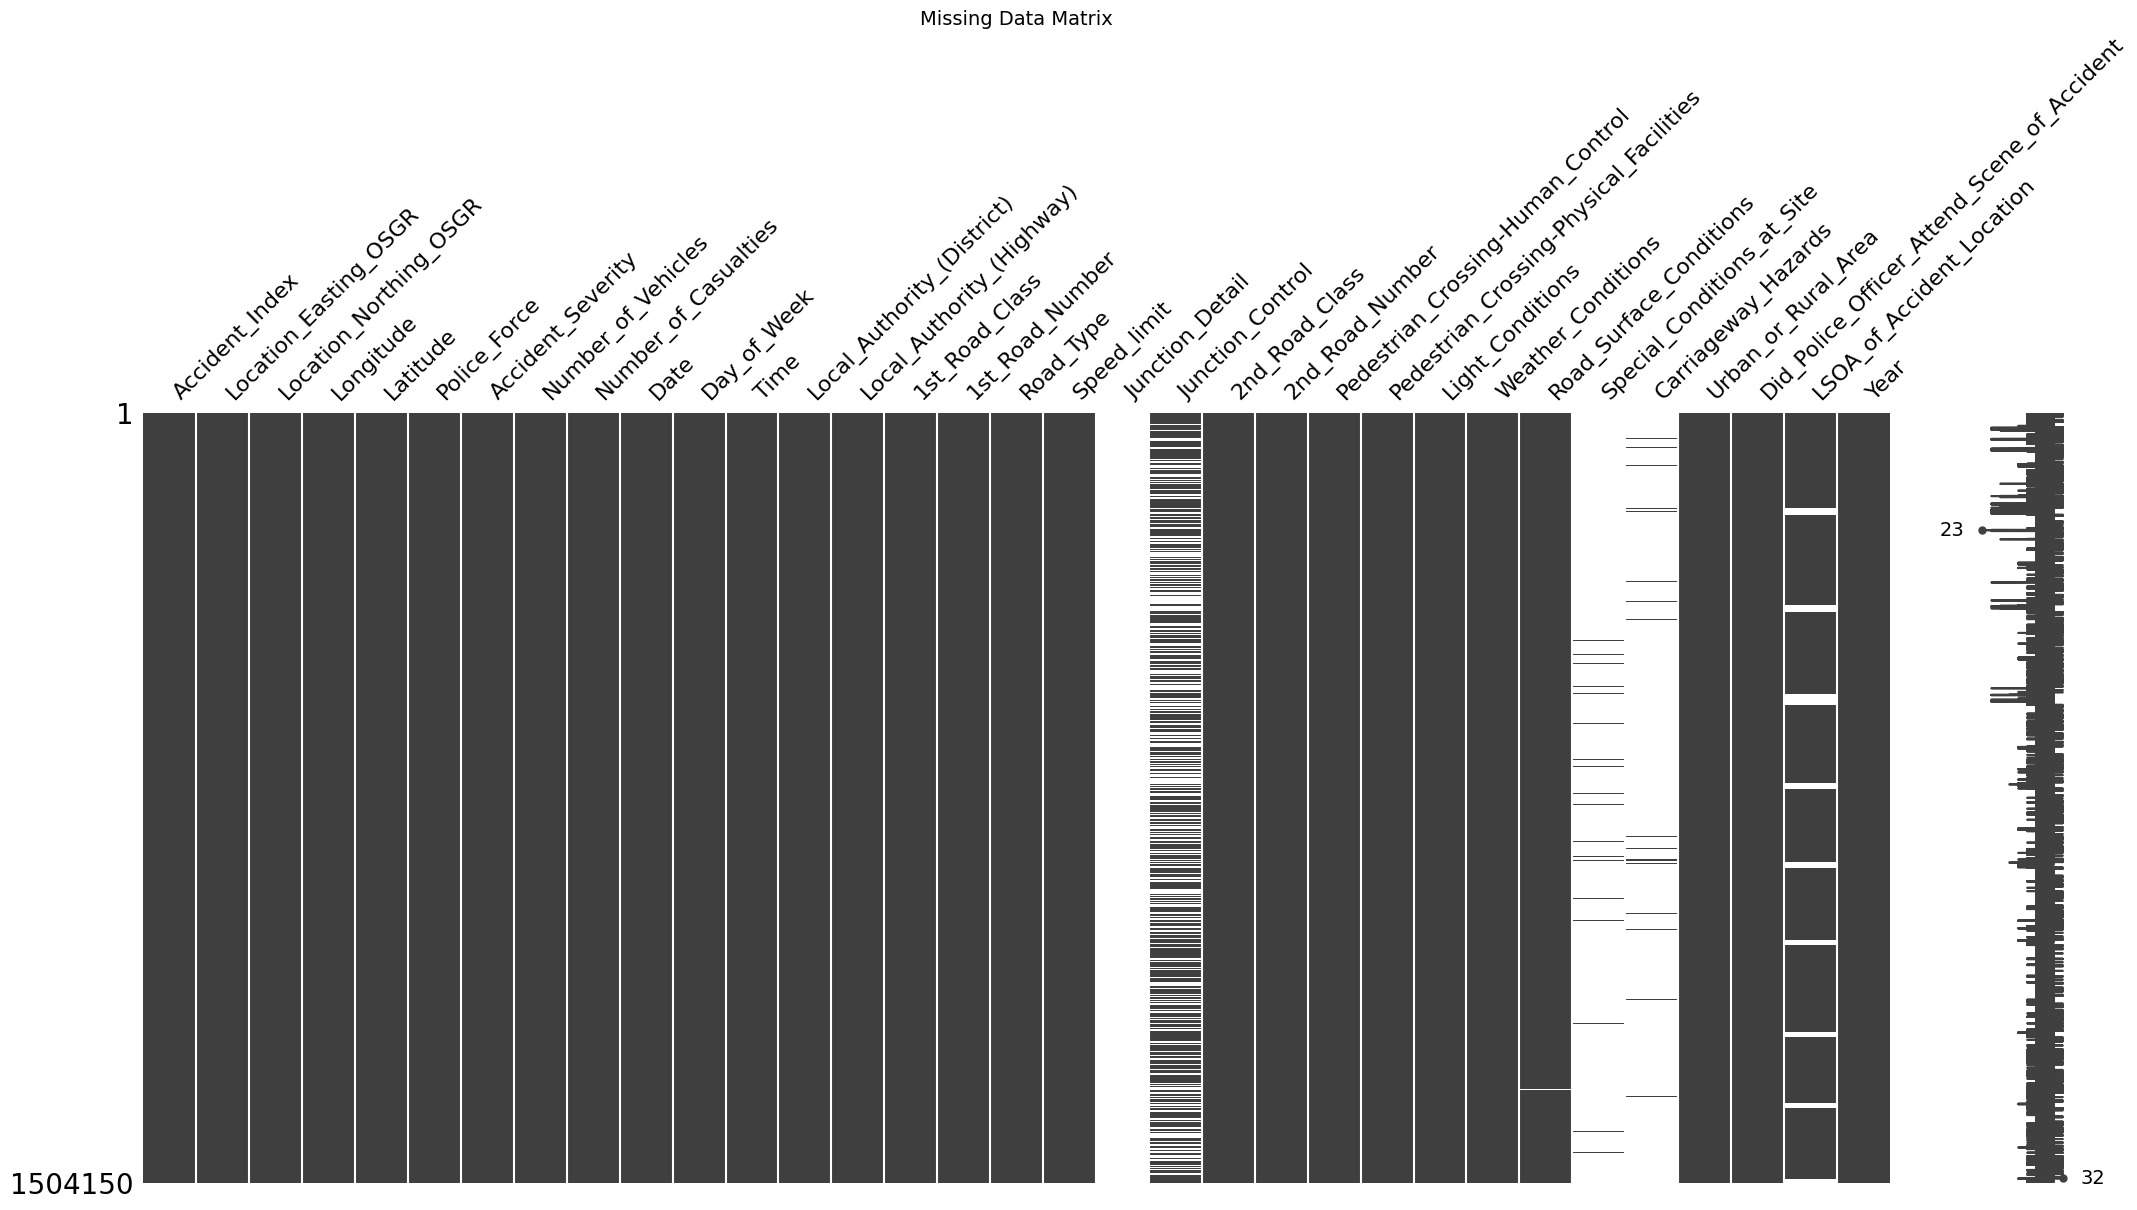

In [60]:
import missingno as msno
import matplotlib.pyplot as plt

# Eksik veri matrisini çiz
msno.matrix(df)
plt.title("Missing Data Matrix", fontsize=14)
plt.show()

In [61]:
# 1. Belirlenen eşik değerin üstündeki sütunları bul (örneğin %50)
threshold = 50
columns_to_drop = missing_percent[missing_percent > threshold].index.tolist()

# 2. Hangi sütunların düşürüleceğini yazdır
print(f"Şu sütunlar % {threshold}’den fazla eksik veri içeriyor ve silinecek:\n{columns_to_drop}")

# 3. Bu sütunları veri setinden çıkar
df = df.drop(columns=columns_to_drop)

Şu sütunlar % 50’den fazla eksik veri içeriyor ve silinecek:
['Junction_Detail', 'Special_Conditions_at_Site', 'Carriageway_Hazards']


In [62]:
for i, col in enumerate(df.columns, 1):
    print(f"{i}. {col}")

1. Accident_Index
2. Location_Easting_OSGR
3. Location_Northing_OSGR
4. Longitude
5. Latitude
6. Police_Force
7. Accident_Severity
8. Number_of_Vehicles
9. Number_of_Casualties
10. Date
11. Day_of_Week
12. Time
13. Local_Authority_(District)
14. Local_Authority_(Highway)
15. 1st_Road_Class
16. 1st_Road_Number
17. Road_Type
18. Speed_limit
19. Junction_Control
20. 2nd_Road_Class
21. 2nd_Road_Number
22. Pedestrian_Crossing-Human_Control
23. Pedestrian_Crossing-Physical_Facilities
24. Light_Conditions
25. Weather_Conditions
26. Road_Surface_Conditions
27. Urban_or_Rural_Area
28. Did_Police_Officer_Attend_Scene_of_Accident
29. LSOA_of_Accident_Location
30. Year


In [63]:
df.shape

(1504150, 30)

# Kalan Eksik Verilerin Analizi

Veri setinde kalan eksik verilerin yerini dolduracağız ya da sileceğiz.

In [64]:
missing_percent = df.isnull().mean() * 100
missing_percent_sorted = missing_percent.sort_values(ascending=False)
print(missing_percent_sorted)

Junction_Control                               40.078117
LSOA_of_Accident_Location                       7.195958
Did_Police_Officer_Attend_Scene_of_Accident     0.194263
Road_Surface_Conditions                         0.130173
Weather_Conditions                              0.008377
Time                                            0.007778
Location_Northing_OSGR                          0.006715
Longitude                                       0.006715
Latitude                                        0.006715
Location_Easting_OSGR                           0.006715
Pedestrian_Crossing-Physical_Facilities         0.002260
Pedestrian_Crossing-Human_Control               0.001130
2nd_Road_Number                                 0.000000
Accident_Index                                  0.000000
Light_Conditions                                0.000000
Urban_or_Rural_Area                             0.000000
2nd_Road_Class                                  0.000000
1st_Road_Number                

In [65]:
# 1. Çok eksik sütunu kategorik olarak 'Unknown' yap
df['Junction_Control'] = df['Junction_Control'].fillna('Unknown')

# 2. Kategorik eksikleri mod (en sık) ile doldur
for col in ['Road_Surface_Conditions', 'Weather_Conditions', 'Did_Police_Officer_Attend_Scene_of_Accident']:
    df[col] = df[col].fillna(df[col].mode()[0])

# 3. Diğer kategorik sütunlarda eksikleri "None"/"Unknown" gibi değerle doldur
df['LSOA_of_Accident_Location'] = df['LSOA_of_Accident_Location'].fillna('Unknown')
df['Pedestrian_Crossing-Physical_Facilities'] = df['Pedestrian_Crossing-Physical_Facilities'].fillna('None')
df['Pedestrian_Crossing-Human_Control'] = df['Pedestrian_Crossing-Human_Control'].fillna('None')

# 4. Sayısal ve konum verilerinde çok küçük eksikler varsa: satırları sil
df = df.dropna(subset=['Longitude', 'Latitude', 'Location_Easting_OSGR', 'Location_Northing_OSGR'])

# 5. Time eksikleri için
df['Time'] = df['Time'].fillna('Unknown')

Veri setindeki eksik veriler analiz edildi ve aşağıdaki işlemler uygulandı:

* Junction_Control (%40 eksik) → "Unknown" ile dolduruldu.

Sütun önemli olduğu için tamamen silinmedi, eksikler ayrı kategoriye alındı.

* Kategorik sütunlar (Road_Surface_Conditions, Weather_Conditions, Did_Police_Officer_Attend_Scene_of_Accident) → En sık değerle dolduruldu.

Analizlerde dağılımı bozmayacak şekilde tamamlandı.

* Pedestrian_Crossing sütunları → "None" ile dolduruldu.

Eksik veri, yaya geçidi olmayan yer anlamına gelebileceği için mantıklı bir kategoriyle tamamlandı.

* Konum bilgileri eksik satırlar (Latitude, Longitude vb.) → Silindi.

Sayısal ve mekânsal analizlerde hata yaratmaması için düşük oranlı eksik satırlar çıkarıldı.

* Time sütunu → "Unknown" ile dolduruldu.

Zaman verisi kaybolmasın, ancak eksikler de kontrol edilebilsin diye.

In [66]:
missing_percent = df.isnull().mean() * 100
missing_percent_sorted = missing_percent.sort_values(ascending=False)
print(missing_percent_sorted)

Accident_Index                                 0.0
Location_Easting_OSGR                          0.0
LSOA_of_Accident_Location                      0.0
Did_Police_Officer_Attend_Scene_of_Accident    0.0
Urban_or_Rural_Area                            0.0
Road_Surface_Conditions                        0.0
Weather_Conditions                             0.0
Light_Conditions                               0.0
Pedestrian_Crossing-Physical_Facilities        0.0
Pedestrian_Crossing-Human_Control              0.0
2nd_Road_Number                                0.0
2nd_Road_Class                                 0.0
Junction_Control                               0.0
Speed_limit                                    0.0
Road_Type                                      0.0
1st_Road_Number                                0.0
1st_Road_Class                                 0.0
Local_Authority_(Highway)                      0.0
Local_Authority_(District)                     0.0
Time                           

Görüldüğü üzere eksik veri kalmamıştır. Analize geçebiliriz.

# Trafik akışının değişmesi kazaları nasıl etkiler?

**1. Araç Sayısı vs. Kaza Şiddeti (Boxplot)**

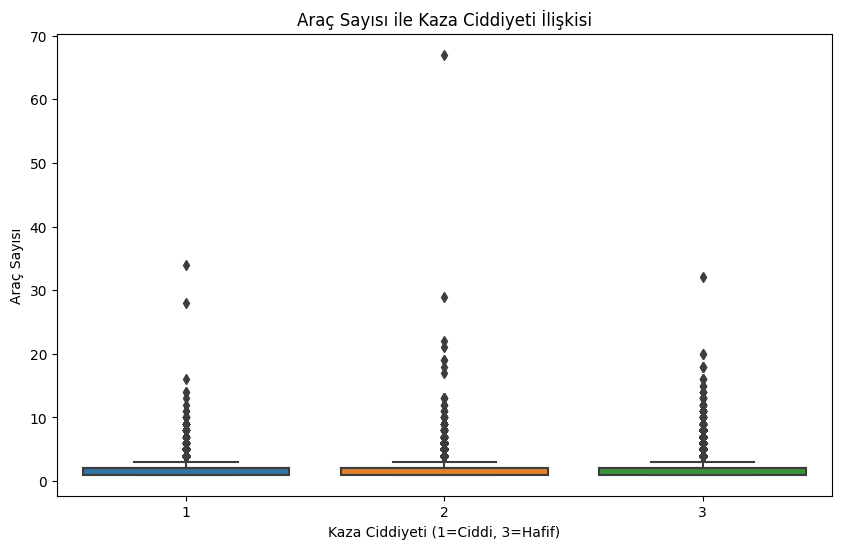

In [67]:
plt.figure(figsize=(10,6))

# Kaza ciddiyetine göre araç sayısının dağılımını gösteren kutu grafiği
sns.boxplot(x='Accident_Severity', y='Number_of_Vehicles', data=df)

plt.title('Araç Sayısı ile Kaza Ciddiyeti İlişkisi')
plt.xlabel('Kaza Ciddiyeti (1=Ciddi, 3=Hafif)')
plt.ylabel('Araç Sayısı')
plt.show()

Gözlem: Tüm Accident_Severity sınıflarında (1: Ciddi, 2: Orta, 3: Hafif) araç sayısı genellikle 1–3 arası.

Dikkat Çeken Durum: Ciddi kazalarda da ortalama araç sayısı çok farklı değil.

**Yorum:** Araç sayısı, doğrudan kaza ciddiyetini belirlemiyor. Yani çok araçlı kazalar illa daha ciddi olmuyor. Ancak uç değerler (outlier) olarak bazı ciddi kazalar 10’dan fazla araca sahip.

**2. Araç Sayısına Göre Kaza Sayısı (Barplot)**

Bu, trafik yoğunluğu (araç sayısı) arttıkça kaç kaza olmuş onu gösterir.

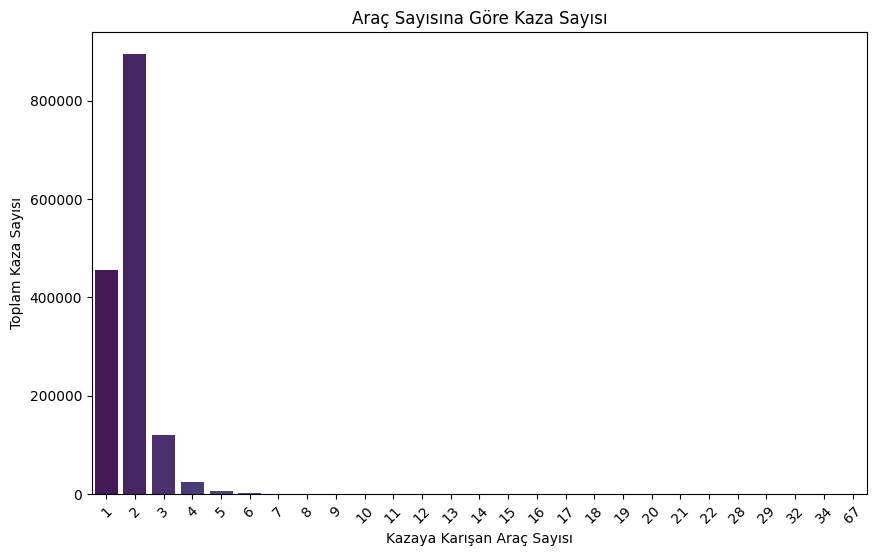

In [68]:
plt.figure(figsize=(10,6))

# Her araç sayısı için toplam kaza sayısı
sns.countplot(x='Number_of_Vehicles', data=df, palette='viridis')

plt.title('Araç Sayısına Göre Kaza Sayısı')
plt.xlabel('Kazaya Karışan Araç Sayısı')
plt.ylabel('Toplam Kaza Sayısı')
plt.xticks(rotation=45)
plt.show()


Gözlem: Araç sayısı 1 ve 2 olan kazalar açık ara en fazla. 3 ve üzeri araçlı kazalar giderek azalıyor.

**Yorum:** Trafik akışı (araç yoğunluğu) artsa da kazaların büyük çoğunluğu tek veya çift araçlı gerçekleşiyor. Bu da bireysel hataların ya da çarpışmaların daha yaygın olduğunu gösteriyor.

**3. Şehir İçi / Kırsal + Araç Sayısı (Heatmap)**

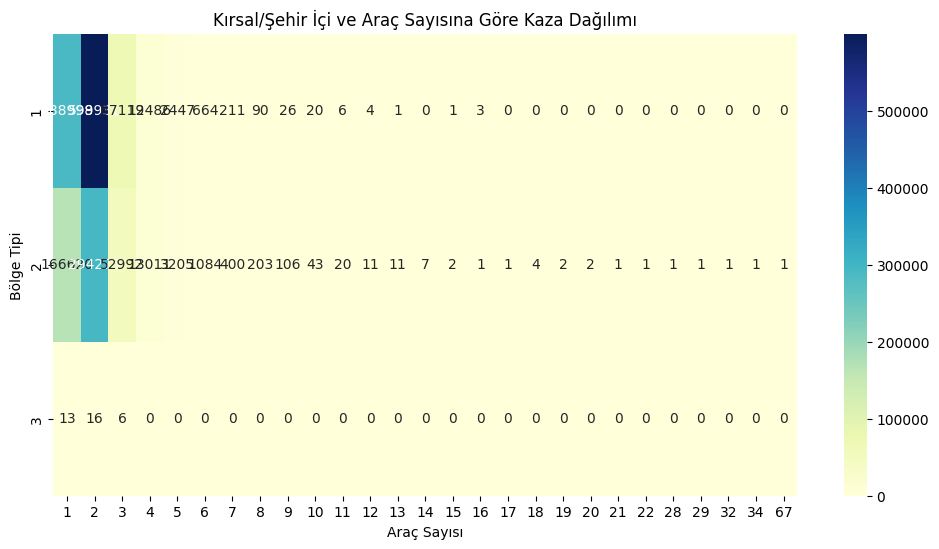

In [69]:
# Gruplama
pivot = df.groupby(['Urban_or_Rural_Area', 'Number_of_Vehicles']).size().unstack().fillna(0)

plt.figure(figsize=(12,6))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='YlGnBu')

plt.title('Kırsal/Şehir İçi ve Araç Sayısına Göre Kaza Dağılımı')
plt.xlabel('Araç Sayısı')
plt.ylabel('Bölge Tipi')
plt.show()

Gözlem:

* Şehir içi kazalar (Urban) çok daha fazla.

* Şehirde 1 ve 2 araçlı kazalar bariz baskın.

* Kırsalda da benzer dağılım var ama toplam sayılar çok daha az.

**Yorum:** Trafik yoğunluğu şehirlerde daha fazla olduğu için kazaların büyük kısmı burada oluyor. Ancak araç sayısı arttıkça hem şehirde hem kırsalda kaza sayısı hızla azalıyor.

# Genel Yorum: Trafik Akışı ve Kazalar

Araç sayısı (yani kazaya karışan araç adedi) bir bakıma trafik akışının yoğunluğunu temsil edebilir.

Veriler gösteriyor ki:

* Trafik akışı arttıkça (çok araçlı kazalar), toplam kaza sayısı azalıyor.

* Ancak bu, trafikte daha çok araç olduğunda daha az kaza olur anlamına gelmez. Bunun yerine, yoğun trafikte daha dikkatli olunabilir ya da hızlar düşer.

* Kazaların çoğu az araçlı ve genellikle şehir içinde oluyor.

# Kaza oranlarını ne artırır?

**1. Hava Durumu ve Kaza Ciddiyeti**

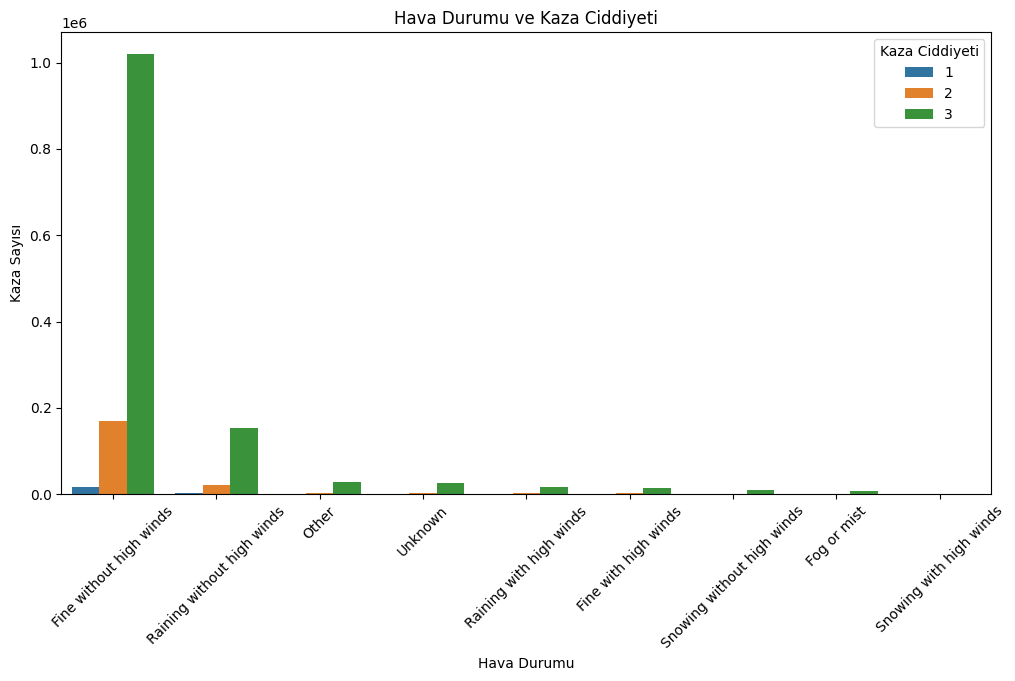

In [70]:
plt.figure(figsize=(12,6))
sns.countplot(x='Weather_Conditions', hue='Accident_Severity', data=df, order=df['Weather_Conditions'].value_counts().index)
plt.title('Hava Durumu ve Kaza Ciddiyeti')
plt.xticks(rotation=45)
plt.xlabel('Hava Durumu')
plt.ylabel('Kaza Sayısı')
plt.legend(title='Kaza Ciddiyeti')
plt.show()

En çok kaza, “Fine without high winds” yani güzel havalarda oluyor.

Ancak bu durum yanıltıcı olabilir çünkü bu hava koşulu en yaygın olanı.

Ciddi kazaların oranı, yağmurlu ve rüzgarlı havalarda (özellikle "Raining with high winds") biraz daha fazla gibi görünüyor.

**Yorum:** Havanın bozulması, özellikle rüzgarlı yağmurla birlikteyse, kaza riskini artırabiliyor.

**2. Yol Yüzeyi ve Kaza Ciddiyeti**

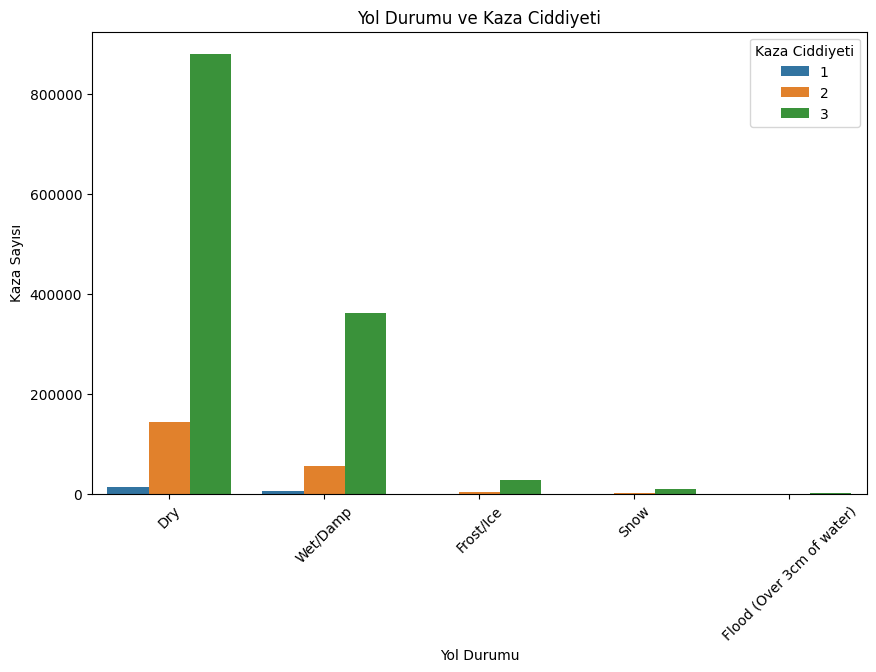

In [71]:
plt.figure(figsize=(10,6))
sns.countplot(x='Road_Surface_Conditions', hue='Accident_Severity', data=df, order=df['Road_Surface_Conditions'].value_counts().index)
plt.title('Yol Durumu ve Kaza Ciddiyeti')
plt.xticks(rotation=45)
plt.xlabel('Yol Durumu')
plt.ylabel('Kaza Sayısı')
plt.legend(title='Kaza Ciddiyeti')
plt.show()


“Dry” (kuru) yüzeylerde kaza sayısı çok yüksek; yine bu yüzeyin yaygınlığından kaynaklanabilir.

Ancak “Wet/Damp” ve “Frost/Ice” gibi ıslak/kaygan zeminlerde ciddi kaza oranı görece daha yüksek.

**Yorum:** Islak, buzlu ve kaygan yollar, kaza ciddiyetini artıran faktörlerden biri.

**3. Işık Koşulları ve Kaza Ciddiyeti**

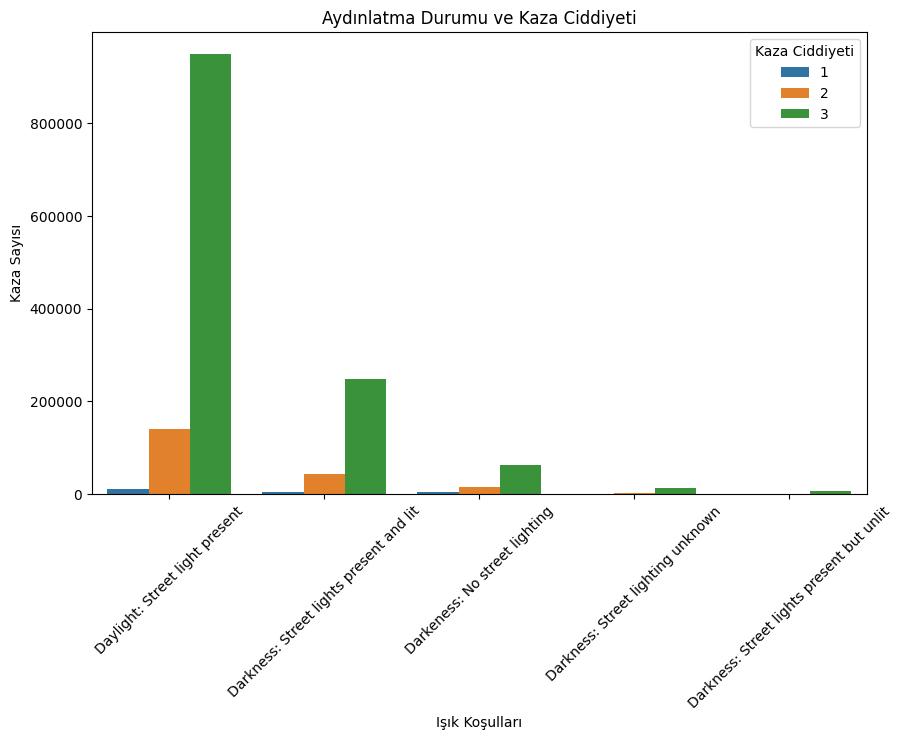

In [72]:
plt.figure(figsize=(10,6))
sns.countplot(x='Light_Conditions', hue='Accident_Severity', data=df, order=df['Light_Conditions'].value_counts().index)
plt.title('Aydınlatma Durumu ve Kaza Ciddiyeti')
plt.xticks(rotation=45)
plt.xlabel('Işık Koşulları')
plt.ylabel('Kaza Sayısı')
plt.legend(title='Kaza Ciddiyeti')
plt.show()

Gündüz ve aydınlatmalı bölgelerde kazalar daha sık. Yine bu kullanım oranı ile ilgili.

Ancak “Darkness: No street lighting” (ışık olmayan karanlık yerler) kategorisinde ciddi kaza oranı fark edilir şekilde daha yüksek.

**Yorum:** Aydınlatmanın yetersiz olduğu karanlık bölgelerde kaza riski ve ciddiyeti artıyor.

**4. Hız Sınırı ve Kaza Ciddiyeti**

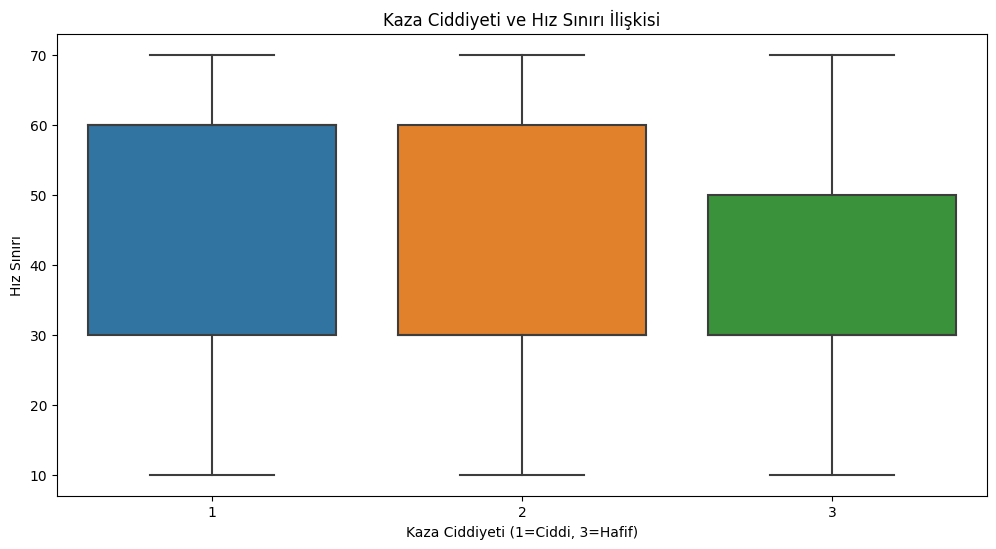

In [73]:
plt.figure(figsize=(12,6))
sns.boxplot(x='Accident_Severity', y='Speed_limit', data=df)
plt.title('Kaza Ciddiyeti ve Hız Sınırı İlişkisi')
plt.xlabel('Kaza Ciddiyeti (1=Ciddi, 3=Hafif)')
plt.ylabel('Hız Sınırı')
plt.show()

Ciddi kazaların (1. seviye) ortalama hız sınırı daha yüksek.

Hafif kazalar genellikle daha düşük hız sınırlı bölgelerde meydana gelmiş.

**Yorum:** Hız sınırı yükseldikçe kaza ciddiyetinin artma ihtimali de artıyor.

# Genel Sonuç: “Kaza oranlarını artıran faktörler”

1. Kötü hava koşulları (özellikle yağmurlu ve rüzgarlı günler)
2. Islak, buzlu veya kaygan yol yüzeyi
3. Aydınlatması yetersiz karanlık bölgeler
4. Yüksek hız sınırına sahip yollar

Bunların her biri hem kaza olasılığını hem de ciddiyetini artıran çevresel risk faktörleridir.

# Zaman içinde kaza oranlarını tahmin edebilir miyiz?

**1- Yıllara Göre Toplam Kaza Sayısı (Trend Analizi)**

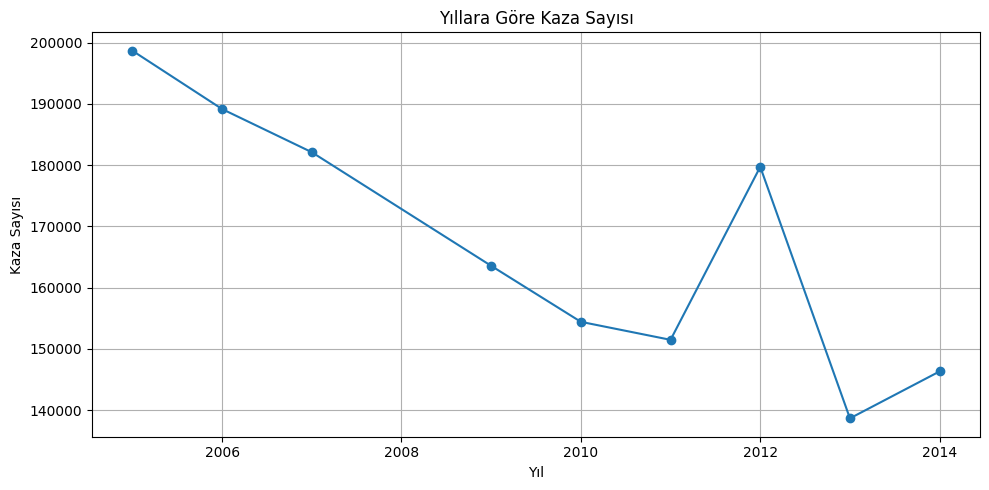

In [74]:
yearly = df['Year'].value_counts().sort_index()

plt.figure(figsize=(10,5))
plt.plot(yearly.index, yearly.values, marker='o', linestyle='-')

plt.title('Yıllara Göre Kaza Sayısı')
plt.xlabel('Yıl')
plt.ylabel('Kaza Sayısı')
plt.grid(True)
plt.tight_layout()
plt.show()

Gözlem: 2005’ten 2010’a kadar kazalarda net bir azalma eğilimi var. 2011’de düşüş devam ederken 2012’de ani bir artış görülüyor, ardından tekrar düşüş.

**Yorum:** Genel olarak yıllar içinde kaza sayısı azalma eğiliminde. 2012’deki sıçrama bir politika değişikliği, veri kaydı artışı ya da özel bir dışsal etkenle açıklanabilir.

**Sonuç:** Uzun vadede kaza sayısı düşme eğiliminde ancak bazı yıllarda keskin dalgalanmalar yaşanabiliyor.

**2. Aylara Göre Kaza Sayısı**

In [75]:
# Date sütunu string durumdaysa datetime formatına çevir
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True, errors='coerce')

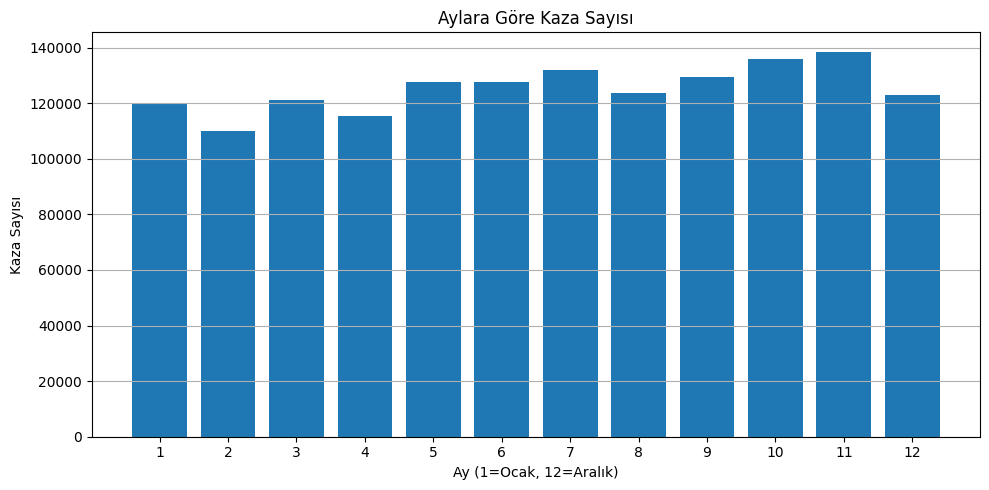

In [76]:
df['Month'] = df['Date'].dt.month
monthly = df['Month'].value_counts().sort_index()

plt.figure(figsize=(10,5))
plt.bar(monthly.index, monthly.values)

plt.title('Aylara Göre Kaza Sayısı')
plt.xlabel('Ay (1=Ocak, 12=Aralık)')
plt.ylabel('Kaza Sayısı')
plt.xticks(range(1,13))
plt.grid(axis='y')
plt.tight_layout()
plt.show()


Gözlem: En çok kaza Kasım ve Ekim aylarında görülüyor. En az kaza ise Şubat ve Nisan’da.

**Yorum:** Sonbahar aylarında artan yağış, günlerin kısalması ve trafik hacmindeki değişimler etkili olabilir. Kışın başındaki buzlanma ve ilkbahar aylarında hava koşullarının iyileşmesiyle düşüş yaşanabilir.

**Sonuç:** Kaza oranları yıl boyunca sabit değil; mevsimsel dalgalanmalar mevcut.

**3. Gün İçinde Saatlik Kaza Dağılımı**

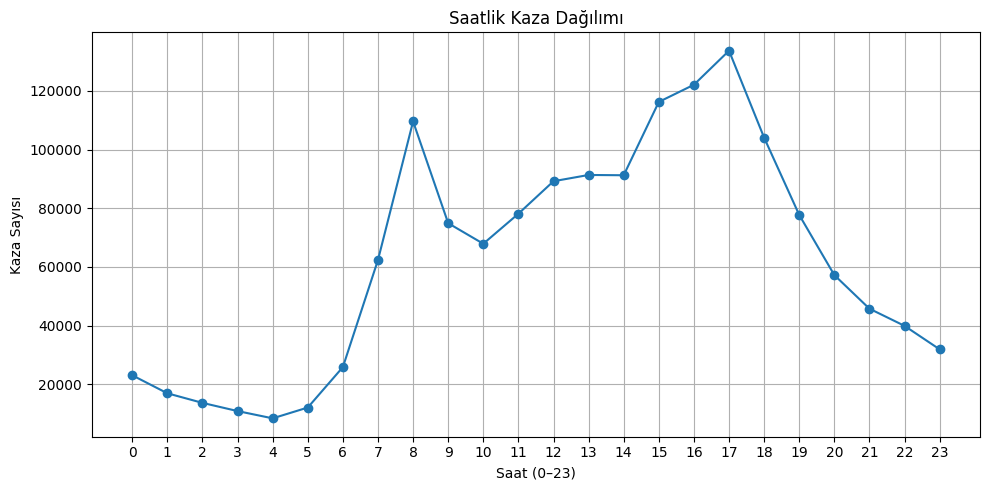

In [77]:
# Saat bilgisini saat (0-23) formatına çevir
df['Hour'] = pd.to_datetime(df['Time'], errors='coerce').dt.hour

hourly = df['Hour'].value_counts().sort_index()

plt.figure(figsize=(10,5))
plt.plot(hourly.index, hourly.values, marker='o')

plt.title('Saatlik Kaza Dağılımı')
plt.xlabel('Saat (0–23)')
plt.ylabel('Kaza Sayısı')
plt.xticks(range(0,24))
plt.grid(True)
plt.tight_layout()
plt.show()

Gözlem: Sabah 8 ve akşam 17 saatlerinde kaza sayısı zirvede. Bu saatler mesai başlangıç ve bitiş saatlerine denk geliyor.

**Yorum:** Trafik yoğunluğunun en fazla olduğu saatlerde kaza riski ciddi biçimde artıyor. Gece 3–5 arası ise minimum kaza görülüyor.

**Sonuç:** Gün içi trafik yoğunluğu kazaları doğrudan etkiliyor; özellikle işe gidiş ve dönüş saatlerinde risk belirgin şekilde yükseliyor.

**4. Doğrusal Regresyon ile Trend ve Tahmin (2015–2016)**

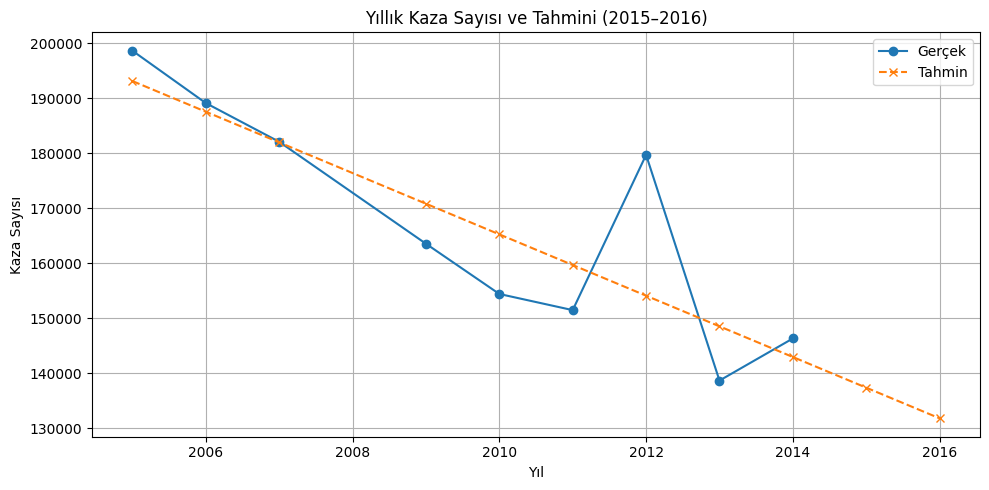

In [78]:
from sklearn.linear_model import LinearRegression
import numpy as np

# Model için veri hazırlanır
X = yearly.index.values.reshape(-1, 1)
y = yearly.values

# Modeli eğit
model = LinearRegression()
model.fit(X, y)

# 2015 ve 2016 için tahmin
future_years = np.array([2015, 2016]).reshape(-1, 1)
X_extended = np.vstack([X, future_years])
y_pred = model.predict(X_extended)

# Grafik
plt.figure(figsize=(10,5))
plt.plot(X.flatten(), y, marker='o', label='Gerçek')
plt.plot(X_extended.flatten(), y_pred, marker='x', linestyle='--', label='Tahmin')

plt.title('Yıllık Kaza Sayısı ve Tahmini (2015–2016)')
plt.xlabel('Yıl')
plt.ylabel('Kaza Sayısı')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Gözlem: Doğrusal regresyon, genel azalan trendi iyi yakalıyor. 2015 ve 2016 için tahmini değerler düşüşe devam ediyor.

*Gerçek veri ile tahmin arasında 2012 gibi sapmalar olsa da genel eğilim doğru modellenmiş.*

**Sonuç:** Yıllık bazda basit modellerle gelecek tahminleri yapılabilir; ancak modelleme doğruluğu için mevsimsel/dönemsel etkiler ve ani dalgalanmalar ayrıca dikkate alınmalıdır.

# Genel Özet: “Zaman içinde kaza oranlarını tahmin edebilir miyiz?”

Evet, uzun vadeli eğilimler gözlemlenebilir ve basit modellerle yakın gelecek tahminleri yapılabilir.

Ancak mevsimsel dalgalanmalar ve saatlik yoğunluklar gibi etkiler dikkate alınmadığında eksik sonuçlar doğabilir.

Daha hassas tahmin için zaman serisi modellemeleri (ARIMA gibi) veya mevsimsel regresyonlar da denenebilir.

# Kırsal ve kentsel alanlar nasıl farklılaştı?

**1. Kırsal vs. Kentsel Alanlarda Toplam Kaza Sayısı**

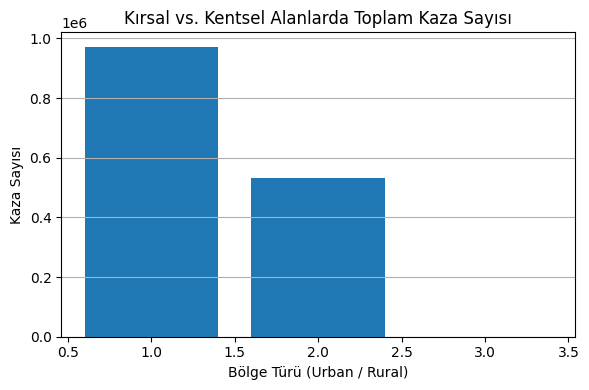

In [79]:
area_counts = df['Urban_or_Rural_Area'].value_counts()

plt.figure(figsize=(6,4))
plt.bar(area_counts.index, area_counts.values)

plt.title('Kırsal vs. Kentsel Alanlarda Toplam Kaza Sayısı')
plt.xlabel('Bölge Türü (Urban / Rural)')
plt.ylabel('Kaza Sayısı')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

Gözlem: Kazaların büyük çoğunluğu kentsel alanlarda gerçekleşmiş. Kırsal alanlar, kentsel bölgelere göre neredeyse yarı yarıya daha az kazaya sahip.

**Yorum:** Bu fark nüfus yoğunluğu, araç trafiği ve yol sayısının şehirlerde daha fazla olmasından kaynaklanabilir.

**Sonuç:** Kentsel alanlar hem daha yoğun hem de daha riskli.

**2. Kaza Ciddiyeti Dağılımı (Urban vs. Rural)**

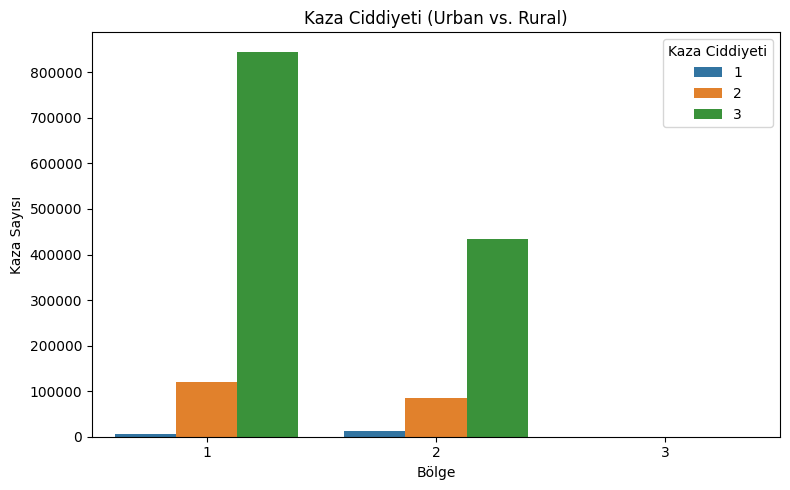

In [80]:
import seaborn as sns

plt.figure(figsize=(8,5))
sns.countplot(x='Urban_or_Rural_Area', hue='Accident_Severity', data=df)

plt.title('Kaza Ciddiyeti (Urban vs. Rural)')
plt.xlabel('Bölge')
plt.ylabel('Kaza Sayısı')
plt.legend(title='Kaza Ciddiyeti')
plt.tight_layout()
plt.show()


Gözlem: Kaza sayısı şehirde daha fazla olsa da ciddi kazaların (1. seviye) oranı kırsalda daha yüksek görünüyor.

**Yorum:** Şehirde hız sınırları daha düşük, yollar daha kontrollü olabilir. Kırsalda ise daha az denetim, daha yüksek hızlar ve geç müdahale nedeniyle daha ağır kazalar yaşanıyor olabilir.

**Sonuç:** Sayı olarak şehir, ciddiyet olarak kırsal daha tehlikeli.

**3. Urban vs. Rural – Günün Saatine Göre Kaza Dağılımı**

In [81]:
df['Hour'] = pd.to_datetime(df['Time'], errors='coerce').dt.hour

In [82]:
df['Urban_or_Rural_Area'] = df['Urban_or_Rural_Area'].map({
    1: 'Urban',
    2: 'Rural',
    3: 'Other'  # Diğerleri için
})

In [83]:
df_filtered = df.dropna(subset=['Hour', 'Urban_or_Rural_Area'])

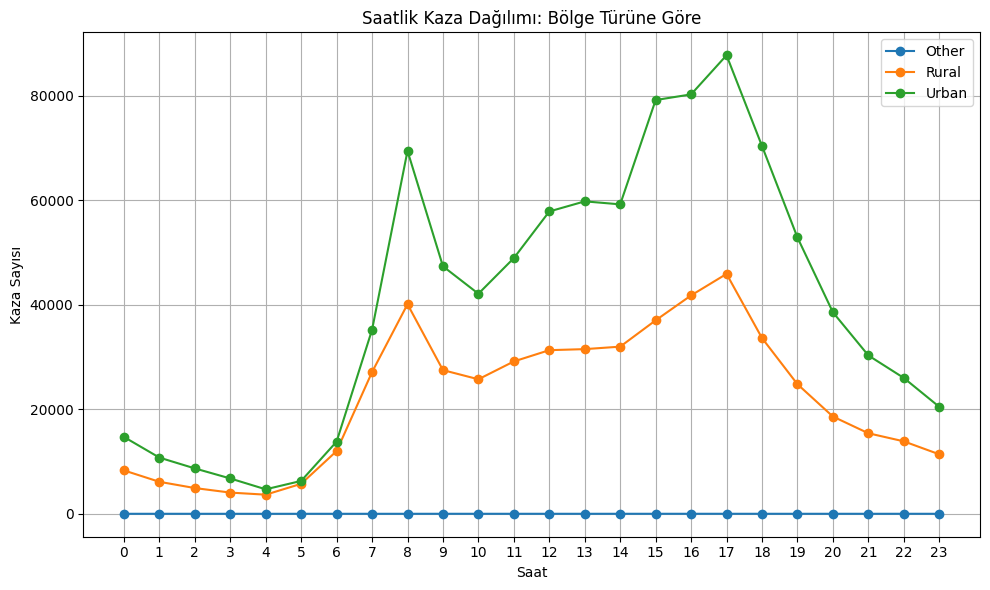

In [84]:
hour_area = df_filtered.groupby(['Hour', 'Urban_or_Rural_Area']).size().unstack().fillna(0)

plt.figure(figsize=(10,6))
for col in hour_area.columns:
    plt.plot(hour_area.index, hour_area[col], marker='o', label=col)

plt.title('Saatlik Kaza Dağılımı: Bölge Türüne Göre')
plt.xlabel('Saat')
plt.ylabel('Kaza Sayısı')
plt.xticks(range(0,24))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Gözlem:

* Kentsel alanlarda sabah 8 ve akşam 17’de pik yapan çok net bir pattern var (mesai saatleri).

* Kırsal alanlarda bu pikler daha az belirgin ve gün boyunca daha dengeli bir dağılım var.

* "Other" kategorisi neredeyse yok sayılabilir.

**Yorum:** Şehirde işe gidiş ve dönüş saatlerinde trafik artışı kazaları artırıyor. Kırsalda trafik akışı daha dağınık.

**Sonuç:** Şehirde kazalar belirgin biçimde zamanla ilişkili; kırsalda daha düz seyrediyor.

**4. Urban vs. Rural – Yol Koşullarına Göre Kaza Dağılımı**

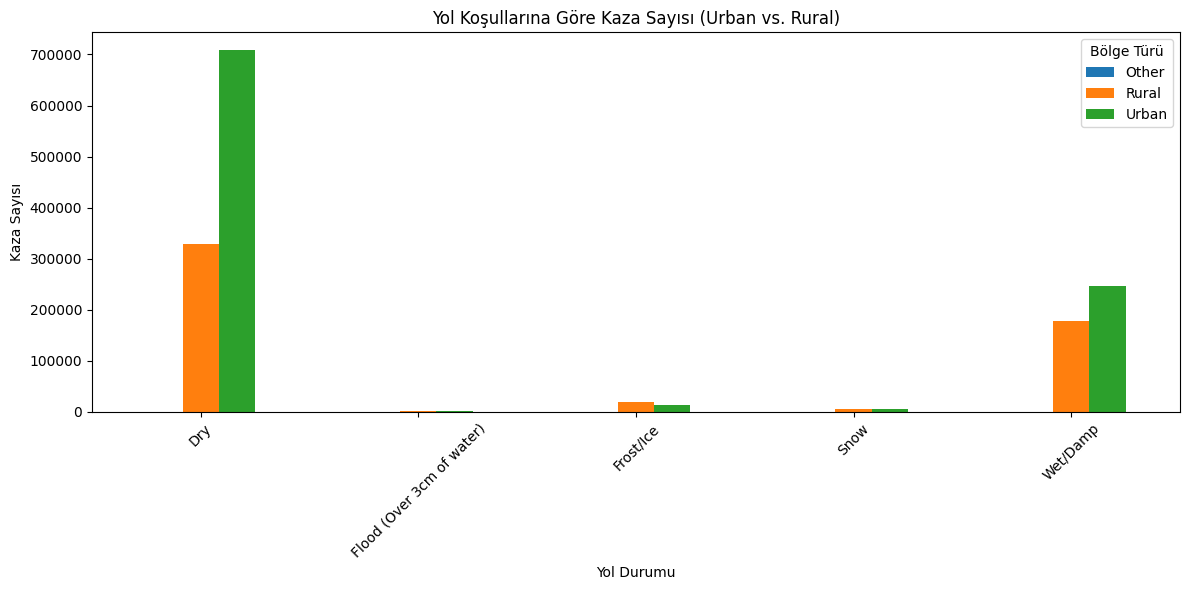

In [85]:
road_area = df.groupby(['Road_Surface_Conditions', 'Urban_or_Rural_Area']).size().unstack().fillna(0)

road_area.plot(kind='bar', figsize=(12,6))
plt.title('Yol Koşullarına Göre Kaza Sayısı (Urban vs. Rural)')
plt.xlabel('Yol Durumu')
plt.ylabel('Kaza Sayısı')
plt.legend(title='Bölge Türü')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Gözlem: Hem şehirde hem kırsalda açık ara en çok kaza kuru yolda oluyor (muhtemelen bu yüzey en sık karşılaşılan olduğu için).

Ancak ıslak/kaygan zeminlerdeki kazaların kırsalda daha yüksek bir pay aldığı gözleniyor.

**Yorum:** Kırsalda yol altyapısı daha kötü olabilir, bu da kötü koşullarda kazaya yatkınlığı artırır.

**Sonuç:** Zemin koşulları kırsalda daha riskli olabilir.

# Genel Özet: “Kırsal ve kentsel alanlar nasıl farklılaştı?”

Evet, bölgesel farklılıklar açık şekilde gözlemlenebilir ve temel karşılaştırmalarla kaza dağılımı hakkında anlamlı çıkarımlar yapılabilir.

Ancak saatlik yoğunluklar, yol koşulları ve kaza ciddiyeti gibi değişkenler dikkate alınmadığında tablo eksik kalabilir.

Daha kapsamlı analiz için bölge-temelli segmentasyon, çok değişkenli regresyon modelleri ya da mekânsal veri analitiği gibi daha gelişmiş yöntemler denenebilir.

# SONUÇ

Yapılan analizler, trafik kazalarının zamansal, mekânsal ve çevresel faktörlere bağlı olarak anlamlı şekilde farklılaştığını ortaya koymuştur. Yıllar içinde kaza sayılarında genel bir azalma eğilimi gözlenirken, gün içi saatler ve yılın belirli aylarında kazaların yoğunlaştığı tespit edilmiştir. Kentsel bölgelerde kazalar daha sık meydana gelirken, kırsal bölgelerde daha ciddi ve ölümcül kazalar öne çıkmaktadır. Yol koşulları, hava durumu ve ışıklandırma gibi çevresel faktörler de kazaların hem sayısını hem şiddetini etkilemektedir. Bu bulgular, trafik güvenliği politikalarının zamana, mekâna ve koşullara göre farklılaşması gerektiğini; riskin yalnızca sıklıkla değil, ciddiyetle de değerlendirilmesi gerektiğini göstermektedir. Ayrıca elde edilen düzenlilikler, gelecekteki kazaların tahmini için temel teşkil edebilir; ancak daha hassas öngörüler için ileri düzey modelleme tekniklerinin kullanılması önerilir.